# Smart Waste Sorter · 02 Generative Adversarial Networks

**Week 2 milestone.** The trash class has the fewest images, and week 1 probably showed the weakest F1 there.
Can a GAN make extra trash images that help the classifier?

- **Part A:** a DCGAN trained on the trash class only, at 64 × 64
- **Part B:** retrain the week-1 ResNet-18 with 300 generated trash images added, and compare

Runtime → **T4 GPU**. Run `00_setup_and_data` first.

In [2]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="NIYOMUGENGA MARIE CLAIRE")

import time, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
dev = ws.device()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Team: NIYOMUGENGA MARIE CLAIRE | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · DCGAN on the trash class
Pixels are scaled to [−1, 1] to match the generator's `tanh` output. Flips and small crops stretch the
roughly 100 training images a little further.

In [6]:
from torch.utils.data import DataLoader
from torchvision import transforms as T
split = ws.load_split()
trash_paths = split[(split.split == "train") & (split.label == "trash")].path.tolist()
gan_tf = T.Compose([T.RandomResizedCrop(64, scale=(0.8, 1.0)), T.RandomHorizontalFlip(), T.ToTensor(),
                    T.Normalize((0.5,) * 3, (0.5,) * 3)])
trash_ds = ws.WasteDataset(trash_paths, [ws.CLASSES.index("trash")] * len(trash_paths), gan_tf)
trash_dl = DataLoader(trash_ds, batch_size=32, shuffle=True, drop_last=len(trash_ds) > 32)
print(len(trash_ds), "trash training images")

96 trash training images


**TODO 1 · Generator.** Map a noise vector `z` of shape (N, 100, 1, 1) to an image of shape (N, 3, 64, 64)
with `ConvTranspose2d` layers, following the DCGAN recipe from the lecture:

`100 → 512×4×4 → 256×8×8 → 128×16×16 → 64×32×32 → 3×64×64`

Use `ConvTranspose2d(c_in, c_out, 4, stride, padding, bias=False)` with stride 1 and padding 0 for the first
layer, stride 2 and padding 1 after that; `BatchNorm2d + ReLU` after every layer except the last, which
ends with `Tanh`.

In [10]:
Z = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        def up(cin, cout, stride, pad):
            return [nn.ConvTranspose2d(cin, cout, 4, stride, pad, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True)]
        self.net = nn.Sequential(
            *up(Z, 512, 1, 0),        # 4x4
            *up(512, 256, 2, 1),      # 8x8
            *up(256, 128, 2, 1),      # 16x16
            *up(128, 64, 2, 1),       # 32x32
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),   # 64x64
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z)

**TODO 2 · Discriminator.** The mirror image: `3×64×64 → 64×32×32 → 128×16×16 → 256×8×8 → 512×4×4 → 1`.
Use `Conv2d(c_in, c_out, 4, 2, 1, bias=False)` and `LeakyReLU(0.2)`; `BatchNorm2d` on every layer except the
first. The last layer is `Conv2d(512, 1, 4, 1, 0)` followed by `Flatten`; output one **logit** per image
(no sigmoid: we use `BCEWithLogitsLoss`).

In [11]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 64, 4, 2, 1, bias=False), nn.LeakyReLU(0.2, True),                                  # 32x32
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2, True),           # 16x16
            nn.Conv2d(128, 256, 4, 2, 1, bias=False), nn.BatchNorm2d(256), nn.LeakyReLU(0.2, True),          # 8x8
            nn.Conv2d(256, 512, 4, 2, 1, bias=False), nn.BatchNorm2d(512), nn.LeakyReLU(0.2, True),          # 4x4
            nn.Conv2d(512, 1, 4, 1, 0),                                                                      # 1x1
            nn.Flatten(),
        )

    def forward(self, x):
        return self.net(x).view(-1)

def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

ws.seed_everything()
G, D = Generator().to(dev), Discriminator().to(dev)
G.apply(init_weights); D.apply(init_weights)
z = torch.randn(4, Z, 1, 1, device=dev)
print("G(z):", tuple(G(z).shape), "| D(G(z)):", tuple(D(G(z)).shape))

G(z): (4, 3, 64, 64) | D(G(z)): (4,)


**TODO 3 · One training step.** Phase A updates D on a real batch (label 1) and a fake batch (label 0);
remember `.detach()`. Phase B updates G so that D labels new fakes as real. Use **label smoothing**: real
labels of 0.9 for D.

In [12]:
bce = nn.BCEWithLogitsLoss()
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))

def train_step(real):
    bs = real.size(0)
    z = torch.randn(bs, Z, 1, 1, device=dev)
    fake = G(z)
    # Phase A: train D (real label 0.9 = label smoothing; detach so G is not updated)
    optD.zero_grad()
    d_loss = bce(D(real), torch.full((bs,), 0.9, device=dev)) + bce(D(fake.detach()), torch.zeros(bs, device=dev))
    d_loss.backward(); optD.step()
    # Phase B: train G (new fakes should be called real; no detach)
    optG.zero_grad()
    g_loss = bce(D(fake), torch.ones(bs, device=dev))
    g_loss.backward(); optG.step()
    return d_loss.item(), g_loss.item()

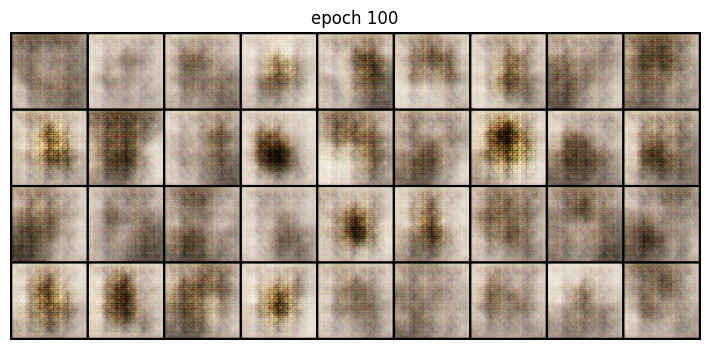

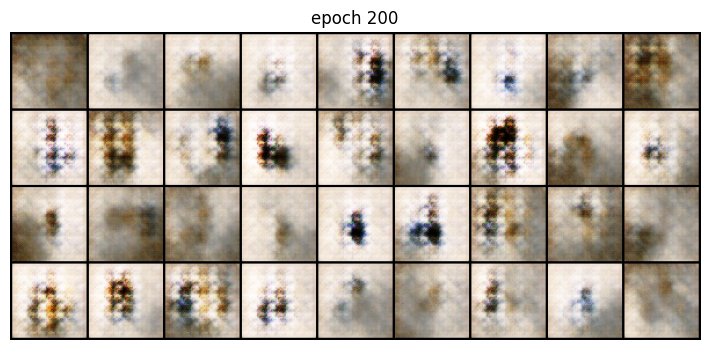

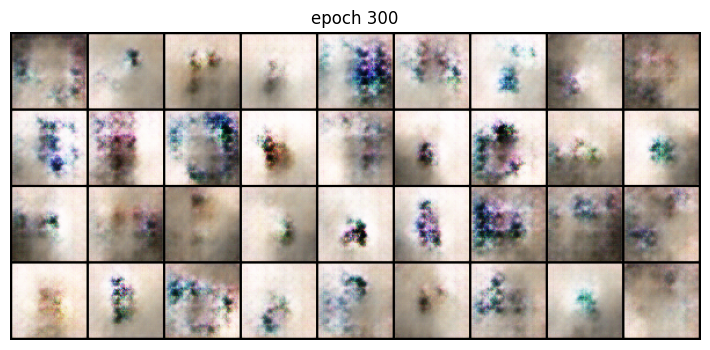

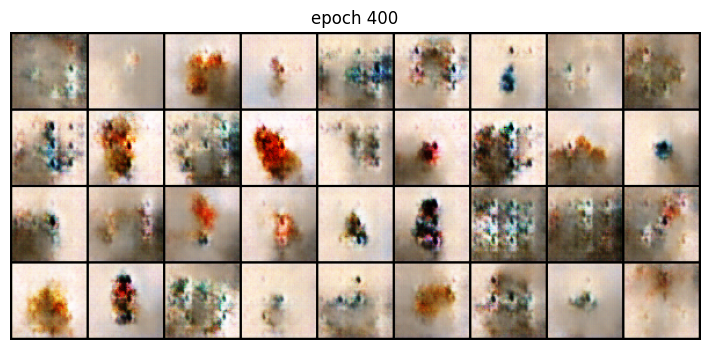

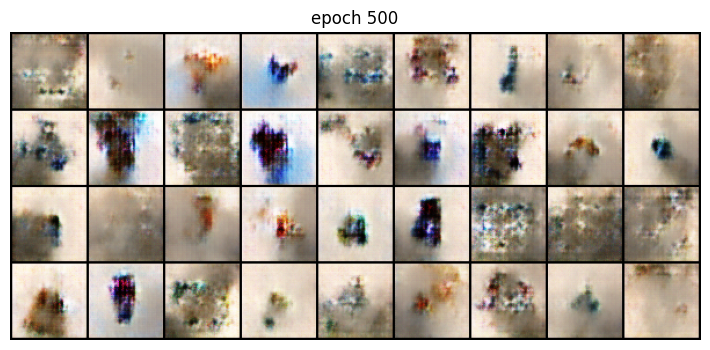

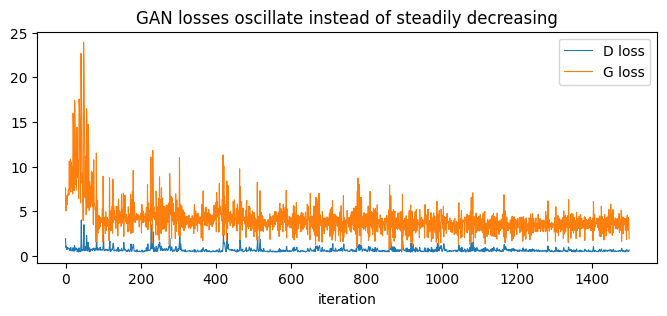

In [13]:
EPOCHS = ws.epochs(500)
fixed_z = torch.randn(36, Z, 1, 1, device=dev)
d_hist, g_hist, t0 = [], [], time.time()
for ep in range(EPOCHS):
    for real, _ in trash_dl:
        d, g = train_step(real.to(dev))
        d_hist.append(d); g_hist.append(g)
    if (ep + 1) % 100 == 0 or ep + 1 == EPOCHS:
        G.eval()
        with torch.no_grad():
            grid = make_grid(G(fixed_z).cpu(), nrow=9, normalize=True, value_range=(-1, 1))
        G.train()
        plt.figure(figsize=(9, 4)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
        plt.title(f"epoch {ep + 1}"); plt.show()
gan_minutes = (time.time() - t0) / 60
torch.save(G.state_dict(), os.path.join(ws.ROOT, "checkpoints", "dcgan_trash_G.pt"))

plt.figure(figsize=(8, 3)); plt.plot(d_hist, label="D loss", lw=0.8); plt.plot(g_hist, label="G loss", lw=0.8)
plt.xlabel("iteration"); plt.legend(); plt.title("GAN losses oscillate instead of steadily decreasing"); plt.show()

Compare: real trash images (left) and generated ones (right). Look for **mode collapse**: many samples
that are nearly identical.

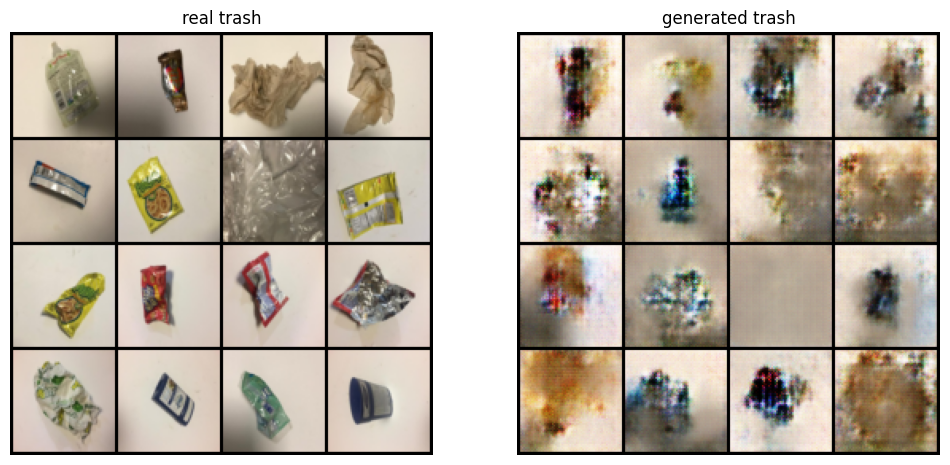

In [14]:
real_batch = torch.stack([trash_ds[i][0] for i in range(min(16, len(trash_ds)))])
G.eval()
with torch.no_grad():
    fake_batch = G(torch.randn(16, Z, 1, 1, device=dev)).cpu()
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, b, t in [(ax[0], real_batch, "real trash"), (ax[1], fake_batch, "generated trash")]:
    a.imshow(make_grid(b, nrow=4, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); a.set_title(t); a.axis("off")
ws.save_figure(fig, "gan_real_vs_fake.png"); plt.show()

## Part B · Do generated images help the classifier?
We train the week-1 ResNet-18 twice with the **same seed and settings**: once on the normal training split,
once with 300 generated trash images added. Only the training data differs.

**TODO 4.** Generate 300 images with `G` (in eval mode, no gradients) and wrap them in
`ws.TensorImages(images, label_id, transform)` with the trash label and the evaluation transform at 224 px.

In [15]:
from torchvision.models import resnet18, ResNet18_Weights
weights = None if ws.SMOKE else ResNet18_Weights.DEFAULT
N_FAKE = 300

def make_resnet18():
    m = resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

G.eval()
with torch.no_grad():
    fake = G(torch.randn(N_FAKE, Z, 1, 1, device=dev)).cpu()
synthetic = ws.TensorImages(fake, ws.CLASSES.index("trash"), ws.transforms_for(224, augment=False))
print(len(synthetic), "synthetic trash images")

local_dl = ws.local_test_loader(224)
runs = {}
for name, extra in [("ResNet-18 baseline (week 2 rerun)", None), ("ResNet-18 + GAN images", synthetic)]:
    ws.seed_everything()
    model = make_resnet18()
    train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, extra_train=extra)
    minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(5), lr=3e-4)
    test = ws.evaluate(model, test_dl)
    local = ws.evaluate(model, local_dl) if local_dl else None
    runs[name] = test
    ws.log_result(2, name, test, local, params_millions=ws.count_params(model), train_minutes=minutes,
                  notes=f"{N_FAKE if extra else 0} synthetic trash images; GAN trained {gan_minutes:.1f} min")

for name, m in runs.items():
    print(f"{name:35s} acc {m['accuracy']:.3f}  macro-F1 {m['macro_f1']:.3f}  trash F1 {m['trash_f1']:.3f}")

300 synthetic trash images
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 176MB/s]


epoch 1/5  train loss 0.625  val acc 0.852  val macro-F1 0.843
epoch 2/5  train loss 0.157  val acc 0.889  val macro-F1 0.888
epoch 3/5  train loss 0.058  val acc 0.889  val macro-F1 0.889
epoch 4/5  train loss 0.020  val acc 0.918  val macro-F1 0.908
epoch 5/5  train loss 0.013  val acc 0.908  val macro-F1 0.898
Logged: {'method': 'ResNet-18 baseline (week 2 rerun)', 'test_accuracy': '0.9420', 'test_macro_f1': '0.9349', 'trash_f1': '0.8780', 'local_accuracy': '0.2833'}
epoch 1/5  train loss 0.530  val acc 0.765  val macro-F1 0.750
epoch 2/5  train loss 0.149  val acc 0.831  val macro-F1 0.806
epoch 3/5  train loss 0.053  val acc 0.905  val macro-F1 0.893
epoch 4/5  train loss 0.015  val acc 0.913  val macro-F1 0.902
epoch 5/5  train loss 0.008  val acc 0.908  val macro-F1 0.890
Logged: {'method': 'ResNet-18 + GAN images', 'test_accuracy': '0.9340', 'test_macro_f1': '0.9220', 'trash_f1': '0.8421', 'local_accuracy': '0.3667'}
ResNet-18 baseline (week 2 rerun)   acc 0.942  macro-F1 0.935

Check 1: did the GAN images make the model over-predict trash? (instant, no training)

In [16]:
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
t = ws.CLASSES.index("trash")
for name, m in runs.items():
    p, r, f, _ = precision_recall_fscore_support(m["y_true"], m["y_pred"], labels=[t], zero_division=0)
    print(f"{name:35s} trash precision {p[0]:.3f}  recall {r[0]:.3f}  F1 {f[0]:.3f}")
    cm = confusion_matrix(m["y_true"], m["y_pred"], labels=list(range(len(ws.CLASSES))))
    print("   true trash predicted as:", dict(zip(ws.CLASSES, cm[t])))
    print("   predicted trash, true class:", dict(zip(ws.CLASSES, cm[:, t])))

ResNet-18 baseline (week 2 rerun)   trash precision 0.900  recall 0.857  F1 0.878
   true trash predicted as: {'cardboard': np.int64(0), 'glass': np.int64(0), 'metal': np.int64(2), 'paper': np.int64(0), 'plastic': np.int64(1), 'trash': np.int64(18)}
   predicted trash, true class: {'cardboard': np.int64(0), 'glass': np.int64(0), 'metal': np.int64(0), 'paper': np.int64(2), 'plastic': np.int64(0), 'trash': np.int64(18)}
ResNet-18 + GAN images              trash precision 0.941  recall 0.762  F1 0.842
   true trash predicted as: {'cardboard': np.int64(1), 'glass': np.int64(1), 'metal': np.int64(3), 'paper': np.int64(0), 'plastic': np.int64(0), 'trash': np.int64(16)}
   predicted trash, true class: {'cardboard': np.int64(0), 'glass': np.int64(0), 'metal': np.int64(0), 'paper': np.int64(1), 'plastic': np.int64(0), 'trash': np.int64(16)}


Check 2: repeat with 5 seeds (the key one, about 5 minutes)

In [17]:
import io, contextlib, numpy as np
res = {"baseline": [], "+ GAN": []}
for s in [0, 1, 2, 3, 4]:
    for name, extra in [("baseline", None), ("+ GAN", synthetic)]:
        ws.seed_everything(s)
        model = make_resnet18()
        tr, va, te = ws.make_loaders(img_size=224, batch_size=32, extra_train=extra)
        with contextlib.redirect_stdout(io.StringIO()):
            ws.train_classifier(model, tr, va, n_epochs=ws.epochs(5), lr=3e-4)
        m = ws.evaluate(model, te)
        res[name].append((m["accuracy"], m["macro_f1"], m["trash_f1"]))
        print(f"seed {s} {name:9s} acc {m['accuracy']:.3f}  macro-F1 {m['macro_f1']:.3f}  trash F1 {m['trash_f1']:.3f}")
for name, v in res.items():
    a = np.array(v)
    print(f"{name:9s} mean±std  acc {a[:,0].mean():.3f}±{a[:,0].std():.3f}  "
          f"macro-F1 {a[:,1].mean():.3f}±{a[:,1].std():.3f}  trash F1 {a[:,2].mean():.3f}±{a[:,2].std():.3f}")

seed 0 baseline  acc 0.945  macro-F1 0.942  trash F1 0.927
seed 0 + GAN     acc 0.931  macro-F1 0.924  trash F1 0.872
seed 1 baseline  acc 0.945  macro-F1 0.937  trash F1 0.878
seed 1 + GAN     acc 0.926  macro-F1 0.918  trash F1 0.857
seed 2 baseline  acc 0.939  macro-F1 0.934  trash F1 0.900
seed 2 + GAN     acc 0.937  macro-F1 0.930  trash F1 0.878
seed 3 baseline  acc 0.942  macro-F1 0.932  trash F1 0.872
seed 3 + GAN     acc 0.950  macro-F1 0.942  trash F1 0.884
seed 4 baseline  acc 0.939  macro-F1 0.930  trash F1 0.850
seed 4 + GAN     acc 0.937  macro-F1 0.932  trash F1 0.900
baseline  mean±std  acc 0.942±0.002  macro-F1 0.935±0.004  trash F1 0.885±0.026
+ GAN     mean±std  acc 0.936±0.008  macro-F1 0.929±0.008  trash F1 0.878±0.014


## Stretch ideas
- **Conditional GAN:** feed a class embedding into G and D and generate all six classes.
- **FID:** `torchmetrics.image.fid.FrechetInceptionDistance` compares real and generated feature statistics
  (lower is better). Compute it at epochs 100, 300 and 500.
- Try 100 and 1,000 synthetic images: is there a point where more hurts?

## Questions for your week-2 findings note
1. Did the synthetic images help, hurt or do nothing for trash F1 and macro-F1? Is the difference bigger than noise?
2. Describe the failure samples. Did you see mode collapse?
3. The GAN trained on about 100 images at 64 × 64, and its output is upscaled to 224 × 224. How might that limit it?
4. What did the loss curves tell you, and what did they not tell you?



1. Did the synthetic images help, hurt or do nothing? Is the difference bigger than noise?**

They did not help. I trained ResNet-18 with and without 300 generated trash images, using 5 seeds. Without them, trash F1 was 0.885 ± 0.026, macro-F1 0.935 ± 0.004 and accuracy 0.942 ± 0.002. With them, trash F1 was 0.878 ± 0.014, macro-F1 0.929 ± 0.008 and accuracy 0.936 ± 0.008. The average differences (about −0.007 for trash F1 and −0.006 for macro-F1 and accuracy) are much smaller than the seed-to-seed spread. The baseline's trash F1 alone ranged from 0.850 to 0.927 with no GAN involved, and the test set has only 21 trash images, so one image shifts the score noticeably. My first single run (trash F1 0.878 vs 0.842) looked like a clear drop, but the repeated runs show it was mostly noise. If anything, the generated images were neutral to slightly harmful: accuracy was lower with them in 4 of 5 seeds, though only by 1 to 7 of 379 test images. All five runs use the same 300 images from one GAN training run, so this tests that GAN, not GANs in general.

2. Describe the failure samples. Did you see mode collapse?**

The generated images are blurry, speckled blobs on a pale beige background. The generator learned the background colour and the idea of a dark, multicoloured object near the centre, but not the objects. The real images show crumpled wrappers, foil, tissue and a plastic sachet, each with clear edges. The generated images have no wrapper shapes, edges or labels. They are not identical: they differ in colour (brown, blue-black, yellow) and one is nearly empty beige. But many share the same dark blob in the middle, so the variety is much narrower than in the real set. I'd call this partial mode collapse. Full collapse would mean near-identical images.

3. The GAN trained on about 100 images at 64 × 64 and its output is upscaled to 224 × 224. How might that limit it?

With 96 images (3 batches per epoch), the generator has very little to learn from, and it can easily settle on the average look of the background and a blob instead of the variety of trash objects. At 64 × 64 the images have little fine detail. Upscaling to 224 × 224 only makes the blur bigger and adds no new information. ResNet-18 was pretrained on sharp 224 × 224 photos and is fine-tuned on sharp real trash images, so blurry blobs look very different from the real images. They add little useful information, and could even teach the classifier to treat "blob on a pale background" as trash. A GAN would probably need many more real trash images, or higher resolution, to produce useful ones.

4. What did the loss curves tell you, and what did they not tell you?**

G's loss spiked to about 25 early in training and then stayed noisy at roughly 3 to 5, while D's loss stayed low near the bottom of the plot. That suggests D was winning most of the time, which fits G producing poor images. Neither loss fell steadily, which is expected for a GAN, because each network's loss depends on the other network's current ability. What the curves cannot tell you is whether the images are good, how varied they are, or whether the GAN would help a classifier. A low D loss could mean D is strong or G is weak. I only learned that G was weak by looking at the samples, and that the images did not help by retraining the classifier.

